# 05 — Contrast Limited Adaptive Histogram Equalization (CLAHE)

Uneven illumination makes a single global contrast mapping inadequate. CLAHE builds local mappings while limiting how strongly populated histogram bins dominate them.

## Learning objectives
- Explain tile histograms, clipping, redistribution, and interpolation.
- Implement the histogram-clipping stage with NumPy.
- Compare global equalization, AHE, and CLAHE under uneven illumination.
- Explore clip limits and tile grids while measuring noise amplification.

Run independently with the bundled `skimage.data.camera()` image. The complete interpolated CLAHE algorithm is provided by OpenCV; the NumPy experiment isolates its clipping principle.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
np.set_printoptions(precision=4, suppress=True)

## 1. Local equalization and clipping

AHE uses a neighborhood CDF instead of one image-wide CDF. Tile-based implementations estimate local histograms and interpolate neighboring mappings to avoid abrupt tile boundaries. CLAHE clips histogram counts and redistributes excess before constructing those CDFs.

For tile area $A$, $B$ bins and OpenCV normalized clip parameter $c>0$, the nominal per-bin threshold is

$$T=\max\left(1,\left\lfloor c\frac{A}{B}\right\rfloor\right).$$

With $\tilde h(k)=\min(h(k),T)$, excess is

$$E=\sum_k[h(k)-\tilde h(k)].$$

Uniform redistribution adds approximately $E/B$ to each bin. Integer remainder placement and interpolation are implementation details. Redistribution can raise counts above the initial threshold, so $T$ is not a strict final bound. In OpenCV, `clipLimit=0` disables clipping (AHE); it is not the strongest clipping setting.

`tileGridSize=(g_x,g_y)` specifies the **number of tiles**, not tile dimensions. More tiles mean smaller neighborhoods. Clip values in different libraries need not have the same normalization.

In [2]:
image = data.camera()
y, x = np.mgrid[0:image.shape[0], 0:image.shape[1]]
illumination = 0.25 + 0.75 * x / (image.shape[1] - 1)
uneven = np.clip(np.rint(image.astype(float) * illumination), 0, 255).astype(np.uint8)

# A constant field plus reproducible noise isolates amplification of noise.
rng = np.random.default_rng(42)
noisy_flat = np.clip(np.rint(110 + rng.normal(0, 2, image.shape)), 0, 255).astype(np.uint8)
global_result = cv2.equalizeHist(uneven)
clahe_result = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(uneven)
ahe_result = cv2.createCLAHE(clipLimit=0.0, tileGridSize=(8, 8)).apply(uneven)
assert clahe_result.shape == image.shape and clahe_result.dtype == np.uint8

## 2. Isolate the clipping stage in NumPy

The implementation below conserves counts and distributes the remainder evenly by bin index. This is an educational redistribution rule, not an exact reproduction of OpenCV's remainder placement, padding, LUT scaling, or interpolation. Its local LUT uses a raw CDF. A full manual CLAHE implementation would also need those stages.

Tile area: 4096 | threshold: 32 | conserved count: 4096


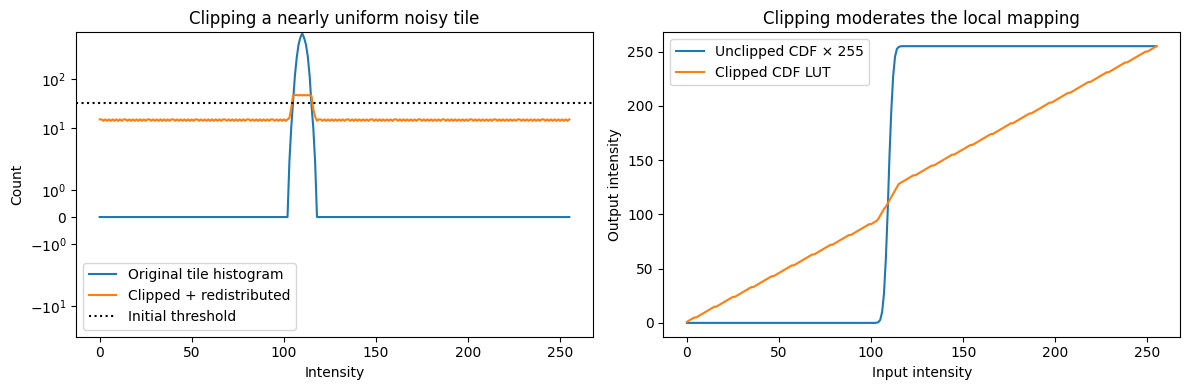

In [3]:
def clip_histogram(counts, clip_parameter):
    counts = np.asarray(counts, dtype=np.int64)
    if counts.ndim != 1 or counts.size == 0 or np.any(counts < 0) or clip_parameter <= 0:
        raise ValueError('Expected nonnegative counts and a positive clipping parameter')
    threshold = max(1, int(clip_parameter * counts.sum() / counts.size))
    clipped = np.minimum(counts, threshold)
    excess = int(counts.sum() - clipped.sum())
    quotient, remainder = divmod(excess, counts.size)
    redistributed = clipped + quotient
    if remainder:
        indices = np.linspace(0, counts.size - 1, remainder, dtype=int)
        redistributed[indices] += 1
    assert redistributed.sum() == counts.sum()
    return redistributed, threshold

tile = noisy_flat[:64, :64]
counts = np.bincount(tile.ravel(), minlength=256)
clipped_counts, threshold = clip_histogram(counts, 2.0)
local_lut = np.rint(255 * np.cumsum(clipped_counts) / tile.size).astype(np.uint8)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(counts, label='Original tile histogram')
axes[0].plot(clipped_counts, label='Clipped + redistributed')
axes[0].axhline(threshold, color='black', linestyle=':', label='Initial threshold')
axes[0].set(xlabel='Intensity', ylabel='Count', title='Clipping a nearly uniform noisy tile', yscale='symlog')
axes[0].legend()
axes[1].plot(255 * np.cumsum(counts) / tile.size, label='Unclipped CDF × 255')
axes[1].plot(local_lut, label='Clipped CDF LUT')
axes[1].set(xlabel='Input intensity', ylabel='Output intensity', title='Clipping moderates the local mapping')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Tile area:', tile.size, '| threshold:', threshold, '| conserved count:', clipped_counts.sum())

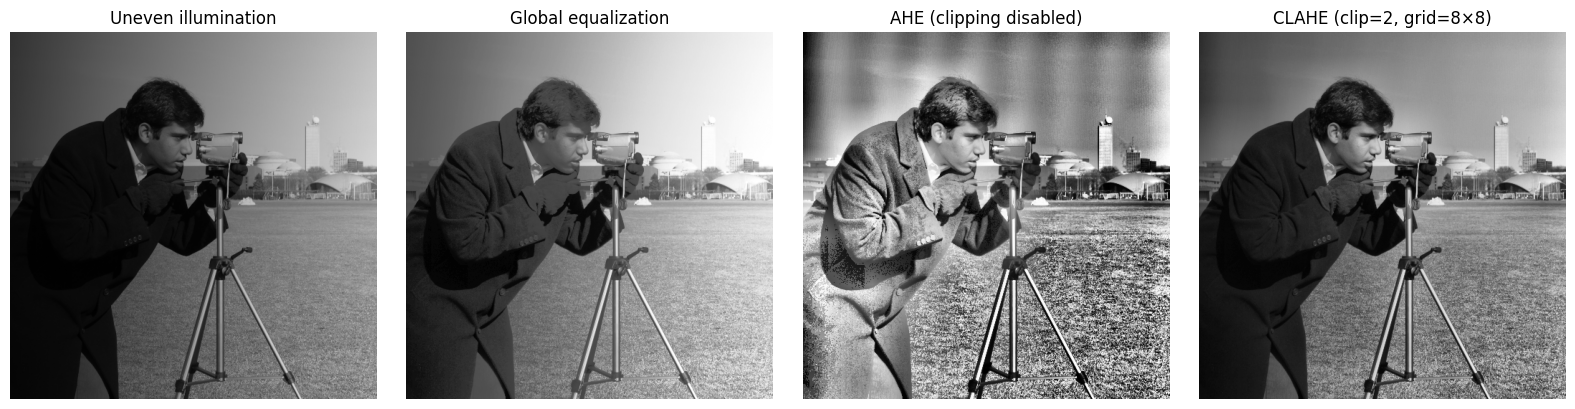

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, arr, title in zip(axes, [uneven, global_result, ahe_result, clahe_result],
                         ['Uneven illumination', 'Global equalization', 'AHE (clipping disabled)', 'CLAHE (clip=2, grid=8×8)']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 3. Parameter sweep

Each row holds grid size fixed and varies the clip limit. Each column holds clip limit fixed and varies locality. Smaller tiles respond to finer structure but estimate histograms from fewer samples. Compare noise standard deviation on the separate flat-field control; scene standard deviation mixes structure and noise and cannot isolate them.

grid      clip   flat-field output std / input std
(4, 4)      1.0   1.991
(4, 4)      2.0   2.950
(4, 4)      8.0   8.473
(8, 8)      1.0   1.981
(8, 8)      2.0   2.908
(8, 8)      8.0   8.471
(16, 16)    1.0   2.009
(16, 16)    2.0   2.962
(16, 16)    8.0   8.500


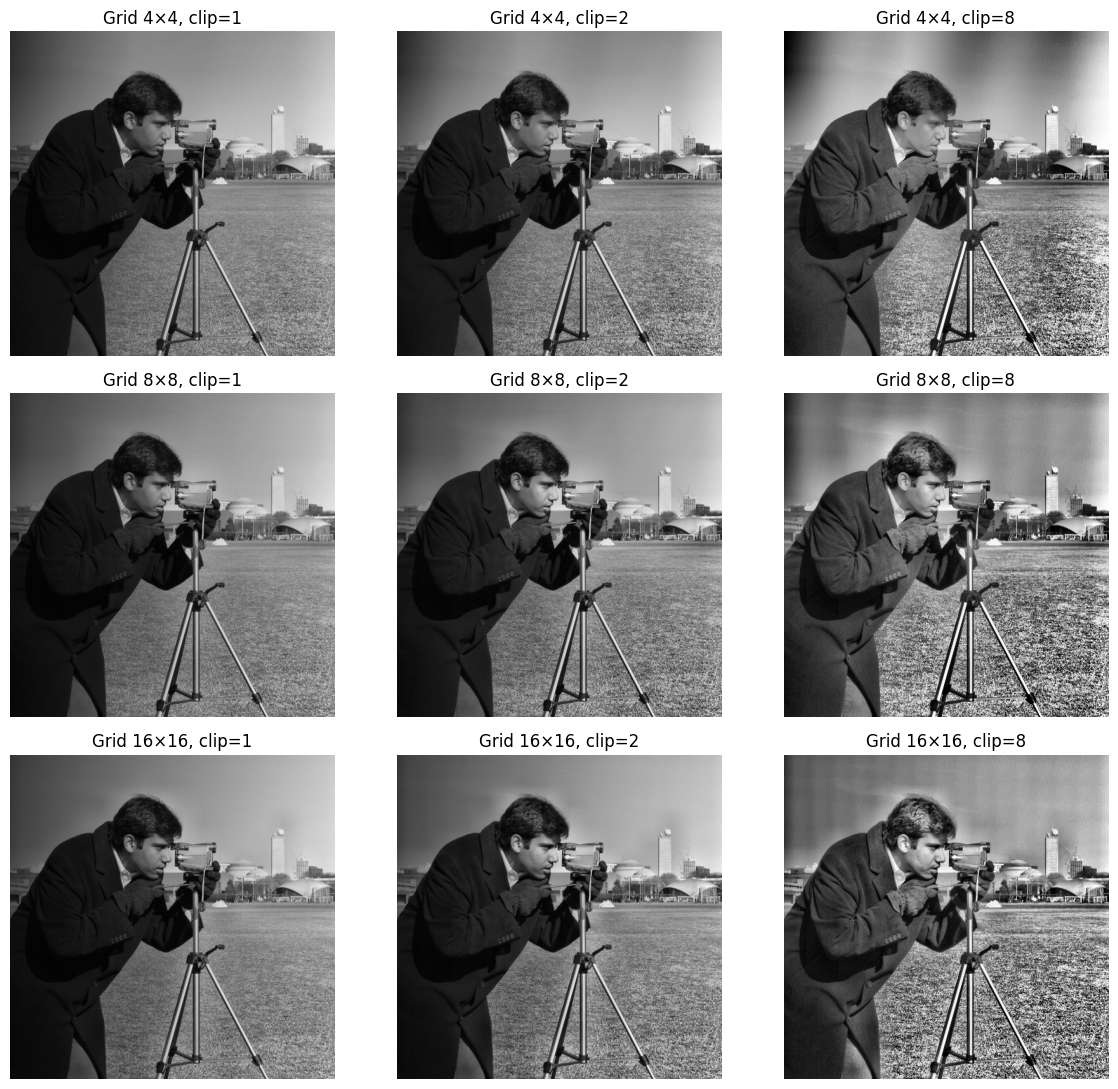

In [5]:
clip_limits = [1.0, 2.0, 8.0]
grids = [(4, 4), (8, 8), (16, 16)]
fig, axes = plt.subplots(len(grids), len(clip_limits), figsize=(12, 11))
print('grid      clip   flat-field output std / input std')
for row, grid in enumerate(grids):
    for col, clip in enumerate(clip_limits):
        operator = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid)
        enhanced = operator.apply(uneven)
        enhanced_noise = operator.apply(noisy_flat)
        print(f'{str(grid):10s} {clip:4.1f}   {enhanced_noise.std() / noisy_flat.std():.3f}')
        axes[row, col].imshow(enhanced, cmap='gray', vmin=0, vmax=255)
        axes[row, col].set_title(f'Grid {grid[0]}×{grid[1]}, clip={clip:g}')
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 4. Why interpolation matters

Independent tile equalization without blending creates discontinuities because identical input levels can receive different outputs in adjacent tiles. The intentionally naive implementation below is a diagnostic baseline, not CLAHE. Compare its visible grid boundaries with the interpolated library result; the library also includes clipping, so this comparison changes more than interpolation alone.

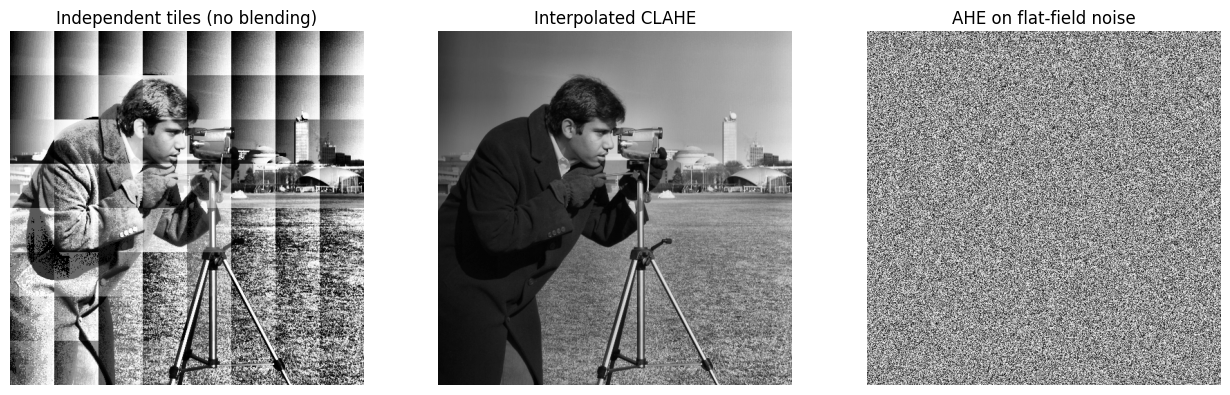

In [6]:
naive_tiles = np.empty_like(uneven)
for row in range(0, image.shape[0], 64):
    for col in range(0, image.shape[1], 64):
        region = uneven[row:row + 64, col:col + 64]
        naive_tiles[row:row + 64, col:col + 64] = cv2.equalizeHist(region)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, arr, title in zip(axes, [naive_tiles, clahe_result, cv2.createCLAHE(0.0, (8, 8)).apply(noisy_flat)],
                         ['Independent tiles (no blending)', 'Interpolated CLAHE', 'AHE on flat-field noise']):
    ax.imshow(arr, cmap='gray', vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Interpretation, limitations, and review

Local mappings can reveal shadow detail without letting the entire image determine the transform. They do not estimate the true illumination field, recover saturated pixels, or distinguish texture from noise. Clipping limits enhancement but does not make it noise-free. Small neighborhoods, high clip limits, and quantization can change appearance substantially. The flat-field ratio is a diagnostic, not a universal image-quality score.

1. For a $64\times64$ tile, 256 bins, and clip limit 2, compute $T$ and explain its units.
2. Why does the redistributed histogram sometimes exceed the clipping threshold?
3. Why can two equal input intensities map to different outputs in CLAHE?
4. Which parameters make tile statistics less reliable, and why?
5. Why should clip-limit numbers not be copied blindly between libraries?

## Summary and connection

CLAHE combines local statistics with controlled nonlinear enhancement. It is useful in Computer Vision under uneven illumination, but its parameters change the distribution of texture and noise. In Deep Learning, preprocessing should be applied consistently and evaluated against the actual downstream task.